# M1.4 · 市场微观结构指标

> 微观结构指标把"流动性、交易成本、知情交易、价格冲击"量化，是高频研究和执行算法的基础。
> 本节计算价差、深度、Kyle's lambda、Amihud、VPIN、OFI、价格冲击；其中回归类指标分别用 statsmodels 与 numpy 实现并对照。
> 注：以下用可复现的模拟高频数据演示（真实 tick 数据工程就绪后可直接替换）。

## 一、指标分类

| 类别 | 指标 |
|---|---|
| 交易成本 | 报价价差、有效价差、实现价差 |
| 流动性厚度 | 盘口深度 |
| 价格冲击 | Kyle's lambda、平方根冲击 |
| 非流动性 | Amihud |
| 知情交易/毒性 | VPIN、订单流不平衡 OFI |

In [1]:
import sys, numpy as np
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
from micro_lab import spreads as sp
from micro_lab import microstructure as ms
rng = np.random.default_rng(42)
n = 300
# 模拟：带符号订单流、价格变化、成交、成交额
signed_vol = rng.normal(0, 1000, n)
true_lambda = 0.002
price_change = 0.01 + true_lambda*signed_vol + rng.normal(0, 0.05, n)
prices = 10 + np.cumsum(price_change)
volumes = np.abs(signed_vol) + rng.uniform(100, 500, n)
dollar_vol = prices * volumes
returns = np.diff(prices, prepend=prices[0]) / prices

## 二、价差与深度

In [2]:
# 报价价差与有效价差
bid, ask = 10.00, 10.02; mid = (bid+ask)/2
print('报价价差=%.2f  相对价差=%.4f' % (sp.quoted_spread(bid, ask),
      sp.relative_spread(bid, ask)))
print('有效价差(买方主动成交@10.02)=%.3f' % sp.effective_spread(10.02, mid, +1))
print('实现价差(未来mid回到10.01)=%.3f' % sp.realized_spread(10.02, 10.01, +1))
book = {10.00: 300, 9.99: 250, 9.98: 400}
print('买3档累计深度=', sp.book_depth(book, n_levels=3, side='bid'))

报价价差=0.02  相对价差=0.0020
有效价差(买方主动成交@10.02)=0.020
实现价差(未来mid回到10.01)=0.020
买3档累计深度= 950


## 三、Kyle's lambda：双实现对账（重点）

Kyle 模型：ΔP = α + λ·订单流 + ε，斜率 λ 衡量单位订单流的价格冲击，越大流动性越差。
下面分别用 statsmodels OLS 与 numpy 最小二乘实现。

In [3]:
# statsmodels 实现
lam_sm, model = ms.kyle_lambda_statsmodels(price_change, signed_vol)
# numpy 手写实现
lam_np, intercept_np = ms.kyle_lambda_numpy(price_change, signed_vol)
print('Kyle lambda (statsmodels) = %.7f' % lam_sm)
print('Kyle lambda (numpy)       = %.7f' % lam_np)
print('两者差异 = %.2e' % abs(lam_sm-lam_np))
print('截距 statsmodels=%.6f  numpy=%.6f' % (model.params[0], intercept_np))
print('statsmodels R^2=%.4f  lambda t值=%.3f' % (model.rsquared, model.tvalues[1]))

Kyle lambda (statsmodels) = 0.0020018
Kyle lambda (numpy)       = 0.0020018
两者差异 = 0.00e+00
截距 statsmodels=0.009511  numpy=0.009511
statsmodels R^2=0.9993  lambda t值=632.635


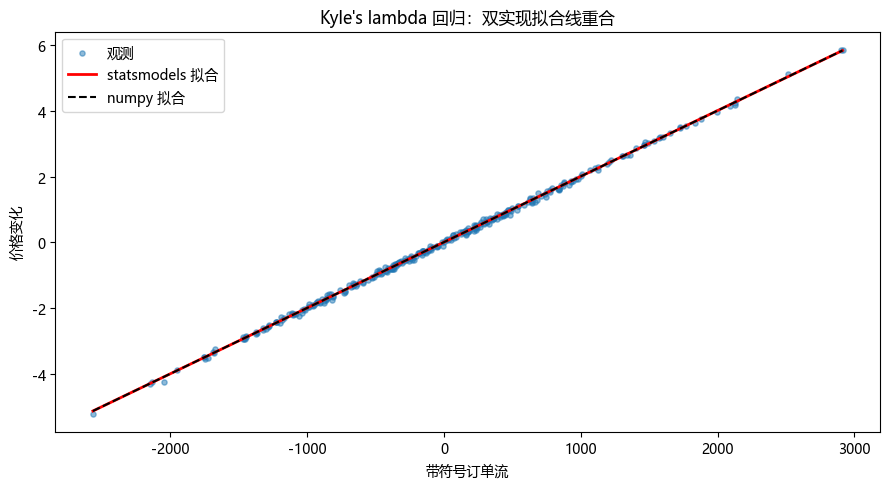

In [4]:
# 可视化：散点 + 两条拟合线（应完全重合）
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(signed_vol, price_change, s=14, alpha=0.5, label='观测')
xline = np.linspace(signed_vol.min(), signed_vol.max(), 50)
ax.plot(xline, model.params[0]+lam_sm*xline, 'r-', lw=2, label='statsmodels 拟合')
ax.plot(xline, intercept_np+lam_np*xline, 'k--', lw=1.5, label='numpy 拟合')
ax.set_xlabel('带符号订单流'); ax.set_ylabel('价格变化')
ax.set_title("Kyle's lambda 回归：双实现拟合线重合")
ax.legend(); plt.tight_layout(); plt.show()

## 四、Amihud 非流动性

In [5]:
illiq = ms.amihud_illiquidity(returns, dollar_vol)
print('Amihud ILLIQ = %.3e' % illiq)
print('含义：每单位成交额对应的价格变动幅度，越大越缺乏流动性。')

Amihud ILLIQ = 2.258e-03
含义：每单位成交额对应的价格变动幅度，越大越缺乏流动性。


## 五、VPIN 与订单流不平衡

In [6]:
vpin_val = ms.vpin(prices, volumes, n_buckets=10)
print('VPIN = %.4f' % vpin_val)
ofi = ms.order_flow_imbalance(10.00, 10.01, 300, 350, 10.02, 10.02, 280, 280)
print('单期 OFI = %.1f（正值表示买盘挂单更积极）' % ofi)

VPIN = 0.1627
单期 OFI = 350.0（正值表示买盘挂单更积极）


## 六、价格冲击曲线

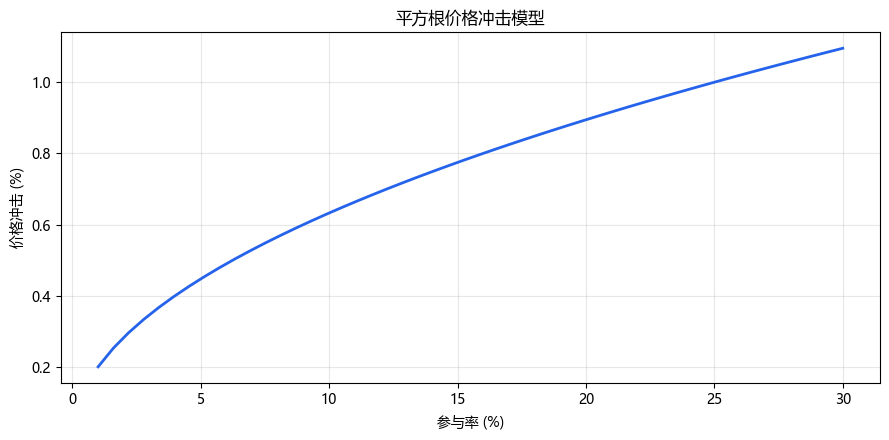

参与率    1% -> 冲击 0.200%
参与率    5% -> 冲击 0.447%
参与率   16% -> 冲击 0.800%


In [7]:
# 平方根冲击：参与率越高，冲击越大但增速递减
rates = np.linspace(0.01, 0.30, 50)
impact = ms.square_root_impact(rates, daily_vol=0.02, coef=1.0)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(rates*100, impact*100, lw=2, color='#2563eb')
ax.set_xlabel('参与率 (%)'); ax.set_ylabel('价格冲击 (%)')
ax.set_title('平方根价格冲击模型')
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()
for r in [0.01, 0.05, 0.16]:
    print('参与率 %4.0f%% -> 冲击 %.3f%%' % (r*100, ms.square_root_impact(r, 0.02)*100))

## 七、小结与面试要点

- 价差衡量即时成本，深度衡量可承接量；Kyle's lambda 与 Amihud 衡量价格冲击/非流动性；VPIN、OFI 衡量知情交易与订单流。
- 回归类指标 statsmodels 与 numpy 双实现结果一致（差异仅浮点误差），可互相验证。
- 平方根冲击随参与率递增、边际递减，是执行算法的核心模型。

**面试高频：**
- Kyle's lambda 是什么、怎么估计？（答：ΔP对订单流回归的斜率，OLS，越大冲击越大）
- Amihud 和 lambda 的区别？（答：Amihud用|r|/成交额，lambda用回归斜率，都衡量非流动性）
- VPIN 衡量什么？（答：订单流毒性/知情交易概率，按成交量篮子的买卖不平衡）
- 有效价差和报价价差的区别？（答：前者看实际成交相对mid，后者看挂单买卖价差）

## 动手练习
1. 用 statsmodels 和 numpy 各跑一次 Kyle 回归并确认结果一致；
2. 改变订单流波动，观察 lambda 估计的稳定性；
3. 计算不同参与率下的冲击，设计一个控制冲击的拆单方案。

---
下一节 **M1.5 高频与另类数据**。